# 05-2. A3 하이퍼파라미터 최적화

A3 전처리 데이터를 고정하고 validation 성능만으로 학습 설정을 선택한다. test는 이 노트북에서 불러오거나 평가하지 않는다.

1. `max_source_length=512`에서 learning rate `1e-5`, `2e-5`, `3e-5` 비교
2. 1단계 최적 learning rate로 source length `512`와 `1024` 비교
3. validation ROUGE-L이 가장 높은 설정을 최종 설정으로 저장

모든 실험은 최대 5 epoch이며 validation loss 기준 early stopping을 적용한다.

## 1. 설정

먼저 `RUN_TRAINING=False`로 데이터와 누수 검사를 확인한다. 이상이 없으면 `True`로 바꾸고 실행한다. 완료된 trial은 자동으로 건너뛴다.

In [10]:
import gc
import json
import os
import random
import re
import sys
import time
from pathlib import Path

PROJECT = Path(r"C:\Users\KDS-30\Desktop\Projects\06_Team_Project4")
assert PROJECT.exists(), "프로젝트 경로를 확인하세요."
assert Path(sys.prefix).resolve() == (PROJECT / ".venv").resolve(), (
    "커널을 Python 3.11 (Team4 News GPU)로 바꾸세요."
)

os.environ["HF_HOME"] = str(PROJECT / ".cache" / "huggingface")
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

FINAL_DIR = PROJECT / "processed_data" / "04-3_final"
RESULTS = PROJECT / "results" / "05-2_hyperparameter_tuning"
RESULTS.mkdir(parents=True, exist_ok=True)

SEED = 42
MODEL_ID = "gogamza/kobart-base-v2"
MAX_TARGET_LENGTH = 256
MAX_EPOCHS = 5
EARLY_STOPPING_PATIENCE = 1
MIN_DELTA = 0.0
LEARNING_RATES = [1e-5, 2e-5]
RUN_TRAINING = True  # 데이터 검증 후 True로 변경
SKIP_COMPLETED = True
SAVE_TRIAL_MODELS = False  # 05-3에서 다시 학습하므로 기본값은 저장하지 않음

print("Python:", sys.version.split()[0])
print("결과 폴더:", RESULTS)

Python: 3.11.9
결과 폴더: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\05-2_hyperparameter_tuning


In [11]:
import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from huggingface_hub import HfApi
from torch import optim
from torch.nn.utils import clip_grad_norm_
from torch.utils.data import DataLoader, RandomSampler, SequentialSampler, TensorDataset
from transformers import AutoTokenizer, BartForConditionalGeneration

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "CUDA를 사용할 수 없습니다."
print("device:", device)
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM(GB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
VRAM(GB): 7.96


## 2. A3 train/validation 고정 및 누수 검사

`processed_data/04-3_final`의 train과 validation만 사용한다. test 파일은 읽지 않는다.

In [12]:
required_paths = [FINAL_DIR / "train.csv", FINAL_DIR / "validation.csv"]
missing_paths = [str(path) for path in required_paths if not path.exists()]
assert not missing_paths, f"필요한 파일이 없습니다: {missing_paths}"

base_columns = ["row_id", "title", "document", "summary"]
train_df = pd.read_csv(FINAL_DIR / "train.csv")[base_columns].reset_index(drop=True)
validation_df = pd.read_csv(FINAL_DIR / "validation.csv")[base_columns].reset_index(drop=True)

for split, frame in {"train": train_df, "validation": validation_df}.items():
    assert frame["row_id"].is_unique, f"{split}: row_id 중복"
    assert frame[["document", "summary"]].notna().all().all()
    assert frame["document"].astype(str).str.strip().ne("").all()
    assert frame["summary"].astype(str).str.strip().ne("").all()

space_pattern = re.compile(r"\s+")
def normalized_values(frame, column):
    return set(frame[column].astype(str).map(lambda value: space_pattern.sub(" ", value).strip()))

leakage_rows = []
for column in ["document", "summary"]:
    overlap = len(normalized_values(train_df, column) & normalized_values(validation_df, column))
    leakage_rows.append({"column": column, "train_validation_overlap": overlap})
leakage_check = pd.DataFrame(leakage_rows)
assert leakage_check["train_validation_overlap"].sum() == 0
leakage_check.to_csv(RESULTS / "split_leakage_check.csv", index=False, encoding="utf-8-sig")

dataset_counts = pd.DataFrame([{
    "dataset": "A3", "train_rows": len(train_df),
    "validation_rows": len(validation_df), "test_used": False,
}])
dataset_counts.to_csv(RESULTS / "dataset_counts.csv", index=False, encoding="utf-8-sig")
display(dataset_counts)
display(leakage_check)
print("검증 통과: A3 train/validation 고정, document/summary 중복 0, test 미사용")

,dataset,train_rows,validation_rows,test_used
0,A3,19236,2240,False


,column,train_validation_overlap
0,document,0
1,summary,0


검증 통과: A3 train/validation 고정, document/summary 중복 0, test 미사용


## 3. 공통 학습 함수

512는 실제 batch 2를 사용한다. 1024는 GPU 메모리를 고려해 실제 batch 1과 gradient accumulation 2를 사용한다. 두 경우 모두 유효 batch size는 2다.

In [13]:
model_revision = HfApi().model_info(MODEL_ID).sha
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID, revision=model_revision, clean_up_tokenization_spaces=False
)
rouge_metric = evaluate.load("rouge")

def reset_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

def batch_config(max_source_length):
    if max_source_length == 1024:
        return {"train_batch_size": 1, "eval_batch_size": 1, "gradient_accumulation_steps": 2}
    return {"train_batch_size": 2, "eval_batch_size": 2, "gradient_accumulation_steps": 1}

def make_dataset(frame, max_source_length):
    source = tokenizer(
        text=frame["document"].astype(str).tolist(),
        padding="max_length", truncation=True, max_length=max_source_length,
        return_token_type_ids=False, return_tensors="pt",
    )
    target = tokenizer(
        text_target=frame["summary"].astype(str).tolist(),
        padding="max_length", truncation=True, max_length=MAX_TARGET_LENGTH,
        return_token_type_ids=False, return_tensors="pt",
    )
    labels = target["input_ids"].clone()
    labels[labels == tokenizer.pad_token_id] = -100
    return TensorDataset(source["input_ids"], source["attention_mask"], labels)

def make_loader(dataset, train_mode, batch_size):
    sampler = RandomSampler(dataset) if train_mode else SequentialSampler(dataset)
    return DataLoader(
        dataset, sampler=sampler, batch_size=batch_size, num_workers=0, pin_memory=True
    )

def train_one_epoch(model, optimizer, dataloader, gradient_accumulation_steps):
    model.train()
    optimizer.zero_grad()
    total_loss = 0.0
    for step, batch in enumerate(dataloader, start=1):
        input_ids, attention_mask, labels = [tensor.to(device) for tensor in batch]
        raw_loss = model(
            input_ids=input_ids, attention_mask=attention_mask, labels=labels
        ).loss
        (raw_loss / gradient_accumulation_steps).backward()
        total_loss += raw_loss.item()
        if step % gradient_accumulation_steps == 0 or step == len(dataloader):
            clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            optimizer.zero_grad()
        if step % 500 == 0:
            print(f"  step {step:,}/{len(dataloader):,} | loss {total_loss / step:.4f}")
    return total_loss / len(dataloader)

def evaluate_loss(model, dataloader):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for batch in dataloader:
            input_ids, attention_mask, labels = [tensor.to(device) for tensor in batch]
            total_loss += model(
                input_ids=input_ids, attention_mask=attention_mask, labels=labels
            ).loss.item()
    return total_loss / len(dataloader)

def generate_predictions(model, dataloader):
    model.eval()
    predictions = []
    with torch.no_grad():
        for step, batch in enumerate(dataloader, start=1):
            input_ids, attention_mask, _ = [tensor.to(device) for tensor in batch]
            generated_ids = model.generate(
                input_ids=input_ids, attention_mask=attention_mask,
                max_length=MAX_TARGET_LENGTH, num_beams=1, do_sample=False,
            )
            predictions.extend(tokenizer.batch_decode(
                generated_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False
            ))
            if step % 200 == 0:
                print(f"  generation {step:,}/{len(dataloader):,}")
    return [prediction.strip() for prediction in predictions]

def trial_id(learning_rate, max_source_length):
    lr_text = f"{learning_rate:.0e}".replace("-", "m")
    return f"lr_{lr_text}_len_{max_source_length}"

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


## 4. trial 실행 함수

validation loss가 한 번 연속 개선되지 않으면 학습을 중단한다. 최고 loss checkpoint에서 validation 문장을 생성하고 ROUGE를 계산한다.

In [14]:
def run_trial(learning_rate, max_source_length):
    name = trial_id(learning_rate, max_source_length)
    trial_dir = RESULTS / name
    trial_dir.mkdir(parents=True, exist_ok=True)
    metrics_path = trial_dir / "validation_metrics.json"

    if SKIP_COMPLETED and metrics_path.exists():
        print(f"[{name}] 완료 결과가 있어 건너뜁니다.")
        return json.loads(metrics_path.read_text(encoding="utf-8"))

    print(f"\n===== {name} =====")
    reset_seed()
    config = batch_config(max_source_length)
    train_dataset = make_dataset(train_df, max_source_length)
    validation_dataset = make_dataset(validation_df, max_source_length)
    train_loader = make_loader(
        train_dataset, train_mode=True, batch_size=config["train_batch_size"]
    )
    validation_loader = make_loader(
        validation_dataset, train_mode=False, batch_size=config["eval_batch_size"]
    )
    print("train / validation:", len(train_dataset), len(validation_dataset))
    print("batch config:", config)

    model = BartForConditionalGeneration.from_pretrained(
        MODEL_ID, revision=model_revision, use_safetensors=True
    ).to(device)
    optimizer = optim.AdamW(model.parameters(), lr=learning_rate, eps=1e-8)
    model_path = trial_dir / "best_model_state.pt"
    best_validation_loss = float("inf")
    best_epoch = None
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, MAX_EPOCHS + 1):
        started = time.perf_counter()
        train_loss = train_one_epoch(
            model, optimizer, train_loader, config["gradient_accumulation_steps"]
        )
        validation_loss = evaluate_loss(model, validation_loader)
        elapsed_minutes = (time.perf_counter() - started) / 60
        history.append({
            "trial": name, "epoch": epoch, "train_loss": train_loss,
            "validation_loss": validation_loss, "minutes": elapsed_minutes,
        })
        print(
            f"{name} epoch {epoch}/{MAX_EPOCHS} | train {train_loss:.4f} | "
            f"validation {validation_loss:.4f} | {elapsed_minutes:.1f}분"
        )

        if validation_loss < best_validation_loss - MIN_DELTA:
            best_validation_loss = validation_loss
            best_epoch = epoch
            epochs_without_improvement = 0
            torch.save(model.state_dict(), model_path)
            print("Saved:", model_path)
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
                print(f"Early stopping: best epoch={best_epoch}")
                break

    history_df = pd.DataFrame(history)
    history_df.to_csv(trial_dir / "loss_history.csv", index=False, encoding="utf-8-sig")
    plt.figure(figsize=(7, 4))
    plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="train")
    plt.plot(
        history_df["epoch"], history_df["validation_loss"],
        marker="o", label="validation",
    )
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.title(f"{name} train and validation loss")
    plt.xticks(history_df["epoch"])
    plt.legend()
    plt.tight_layout()
    plt.savefig(trial_dir / "loss_curve.png", dpi=160)
    plt.show()

    model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
    predictions = generate_predictions(model, validation_loader)
    references = validation_df["summary"].astype(str).tolist()
    rouge_scores = rouge_metric.compute(
        predictions=predictions, references=references,
        tokenizer=lambda text: text.split(), use_stemmer=False,
    )
    metrics = {
        "trial": name, "learning_rate": learning_rate,
        "max_source_length": max_source_length,
        "train_batch_size": config["train_batch_size"],
        "gradient_accumulation_steps": config["gradient_accumulation_steps"],
        "effective_batch_size": (
            config["train_batch_size"] * config["gradient_accumulation_steps"]
        ),
        "best_epoch": best_epoch, "epochs_ran": len(history_df),
        "best_validation_loss": best_validation_loss,
        **{name: score * 100 for name, score in rouge_scores.items()},
    }
    metrics_path.write_text(
        json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    prediction_df = validation_df.copy()
    prediction_df["prediction"] = predictions
    prediction_df.to_csv(
        trial_dir / "validation_predictions.csv", index=False, encoding="utf-8-sig"
    )
    display(pd.Series(metrics, name=name))

    if not SAVE_TRIAL_MODELS:
        model_path.unlink(missing_ok=True)
    del model, optimizer, train_dataset, validation_dataset, train_loader, validation_loader
    gc.collect()
    torch.cuda.empty_cache()
    return metrics

## 5. 1단계: 512에서 learning rate 비교

세 learning rate를 비교하고 validation ROUGE-L이 가장 높은 값을 선택한다. 동률이면 validation loss가 낮은 값을 선택한다.


===== lr_1em05_len_512 =====


You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


train / validation: 19236 2240
batch config: {'train_batch_size': 2, 'eval_batch_size': 2, 'gradient_accumulation_steps': 1}
  step 500/9,618 | loss 0.9281
  step 1,000/9,618 | loss 0.8160
  step 1,500/9,618 | loss 0.7658
  step 2,000/9,618 | loss 0.7322
  step 2,500/9,618 | loss 0.7051
  step 3,000/9,618 | loss 0.6856
  step 3,500/9,618 | loss 0.6697
  step 4,000/9,618 | loss 0.6592
  step 4,500/9,618 | loss 0.6488
  step 5,000/9,618 | loss 0.6387
  step 5,500/9,618 | loss 0.6295
  step 6,000/9,618 | loss 0.6233
  step 6,500/9,618 | loss 0.6170
  step 7,000/9,618 | loss 0.6110
  step 7,500/9,618 | loss 0.6054
  step 8,000/9,618 | loss 0.6006
  step 8,500/9,618 | loss 0.5950
  step 9,000/9,618 | loss 0.5906
  step 9,500/9,618 | loss 0.5867
lr_1em05_len_512 epoch 1/5 | train 0.5859 | validation 0.4951 | 28.1분
Saved: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\05-2_hyperparameter_tuning\lr_1em05_len_512\best_model_state.pt
  step 500/9,618 | loss 0.4266
  step 1,000/9,618 |

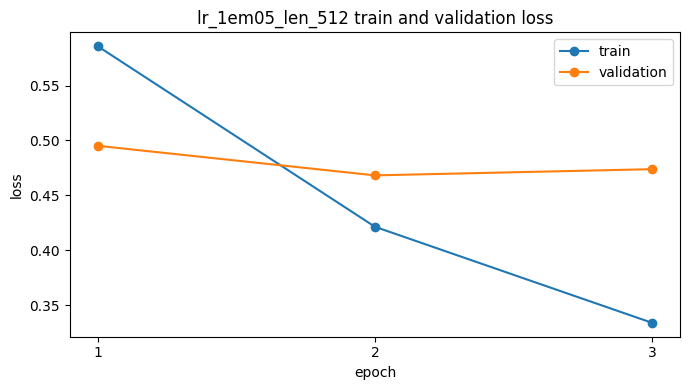

  generation 200/1,120
  generation 400/1,120
  generation 600/1,120
  generation 800/1,120
  generation 1,000/1,120


trial                          lr_1em05_len_512
learning_rate                           0.00001
max_source_length                           512
train_batch_size                              2
gradient_accumulation_steps                   1
effective_batch_size                          2
best_epoch                                    2
epochs_ran                                    3
best_validation_loss                   0.468172
rouge1                                41.472195
rouge2                                34.688928
rougeL                                 37.57224
rougeLsum                             37.579459
Name: lr_1em05_len_512, dtype: object


===== lr_2em05_len_512 =====


You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


train / validation: 19236 2240
batch config: {'train_batch_size': 2, 'eval_batch_size': 2, 'gradient_accumulation_steps': 1}
  step 500/9,618 | loss 0.8675
  step 1,000/9,618 | loss 0.7794
  step 1,500/9,618 | loss 0.7389
  step 2,000/9,618 | loss 0.7117
  step 2,500/9,618 | loss 0.6879
  step 3,000/9,618 | loss 0.6712
  step 3,500/9,618 | loss 0.6575
  step 4,000/9,618 | loss 0.6488
  step 4,500/9,618 | loss 0.6396
  step 5,000/9,618 | loss 0.6308
  step 5,500/9,618 | loss 0.6224
  step 6,000/9,618 | loss 0.6168
  step 6,500/9,618 | loss 0.6115
  step 7,000/9,618 | loss 0.6060
  step 7,500/9,618 | loss 0.6008
  step 8,000/9,618 | loss 0.5965
  step 8,500/9,618 | loss 0.5913
  step 9,000/9,618 | loss 0.5873
  step 9,500/9,618 | loss 0.5839
lr_2em05_len_512 epoch 1/5 | train 0.5831 | validation 0.4999 | 28.1분
Saved: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\05-2_hyperparameter_tuning\lr_2em05_len_512\best_model_state.pt
  step 500/9,618 | loss 0.3945
  step 1,000/9,618 |

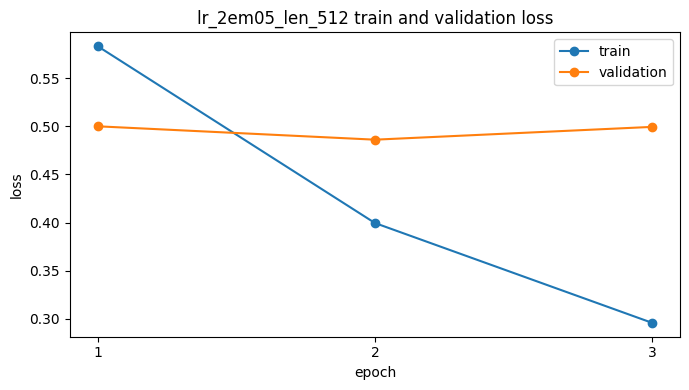

  generation 200/1,120
  generation 400/1,120
  generation 600/1,120
  generation 800/1,120
  generation 1,000/1,120


trial                          lr_2em05_len_512
learning_rate                           0.00002
max_source_length                           512
train_batch_size                              2
gradient_accumulation_steps                   1
effective_batch_size                          2
best_epoch                                    2
epochs_ran                                    3
best_validation_loss                   0.486061
rouge1                                40.527423
rouge2                                 33.59328
rougeL                                36.767733
rougeLsum                             36.775009
Name: lr_2em05_len_512, dtype: object

,trial,learning_rate,max_source_length,train_batch_size,gradient_accumulation_steps,effective_batch_size,best_epoch,epochs_ran,best_validation_loss,rouge1,rouge2,rougeL,rougeLsum
0,lr_1em05_len_512,0.00001,512,2,1,2,2,3,0.468172,41.472195,34.688928,37.572240,37.579459
1,lr_2em05_len_512,0.00002,512,2,1,2,2,3,0.486061,40.527423,33.593280,36.767733,36.775009


선택 learning rate: 1e-05


In [15]:
stage1_rows = []

if RUN_TRAINING:
    for learning_rate in LEARNING_RATES:
        stage1_rows.append(run_trial(learning_rate, max_source_length=512))

    stage1_results = pd.DataFrame(stage1_rows).sort_values(
        ["rougeL", "best_validation_loss"], ascending=[False, True]
    ).reset_index(drop=True)
    stage1_results.to_csv(
        RESULTS / "stage1_learning_rate_results.csv", index=False, encoding="utf-8-sig"
    )
    display(stage1_results)
    best_learning_rate = float(stage1_results.iloc[0]["learning_rate"])
    print("선택 learning rate:", best_learning_rate)
else:
    print("RUN_TRAINING=False: 1단계 학습을 건너뜁니다.")

## 6. 2단계: 512와 1024 비교

1단계에서 선택된 learning rate의 512 결과를 재사용하고 1024 trial만 추가로 학습한다.


===== lr_1em05_len_1024 =====


You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


train / validation: 19236 2240
batch config: {'train_batch_size': 1, 'eval_batch_size': 1, 'gradient_accumulation_steps': 2}
  step 500/19,236 | loss 1.1161
  step 1,000/19,236 | loss 0.9521
  step 1,500/19,236 | loss 0.8847
  step 2,000/19,236 | loss 0.8432
  step 2,500/19,236 | loss 0.8162
  step 3,000/19,236 | loss 0.7911
  step 3,500/19,236 | loss 0.7719
  step 4,000/19,236 | loss 0.7588
  step 4,500/19,236 | loss 0.7465
  step 5,000/19,236 | loss 0.7321
  step 5,500/19,236 | loss 0.7215
  step 6,000/19,236 | loss 0.7132
  step 6,500/19,236 | loss 0.7054
  step 7,000/19,236 | loss 0.6975
  step 7,500/19,236 | loss 0.6922
  step 8,000/19,236 | loss 0.6875
  step 8,500/19,236 | loss 0.6825
  step 9,000/19,236 | loss 0.6770
  step 9,500/19,236 | loss 0.6716
  step 10,000/19,236 | loss 0.6667
  step 10,500/19,236 | loss 0.6623
  step 11,000/19,236 | loss 0.6578
  step 11,500/19,236 | loss 0.6552
  step 12,000/19,236 | loss 0.6517
  step 12,500/19,236 | loss 0.6486
  step 13,000/19,236 

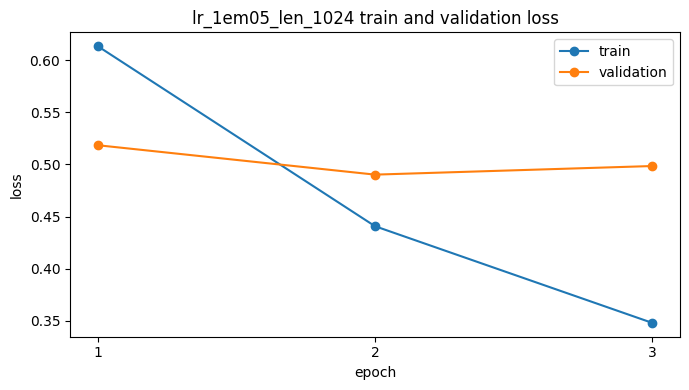

  generation 200/2,240
  generation 400/2,240
  generation 600/2,240
  generation 800/2,240
  generation 1,000/2,240
  generation 1,200/2,240
  generation 1,400/2,240
  generation 1,600/2,240
  generation 1,800/2,240
  generation 2,000/2,240
  generation 2,200/2,240


trial                          lr_1em05_len_1024
learning_rate                            0.00001
max_source_length                           1024
train_batch_size                               1
gradient_accumulation_steps                    2
effective_batch_size                           2
best_epoch                                     2
epochs_ran                                     3
best_validation_loss                    0.490245
rouge1                                 38.221776
rouge2                                 32.068326
rougeL                                 34.656395
rougeLsum                              34.652475
Name: lr_1em05_len_1024, dtype: object

,trial,learning_rate,max_source_length,train_batch_size,gradient_accumulation_steps,effective_batch_size,best_epoch,epochs_ran,best_validation_loss,rouge1,rouge2,rougeL,rougeLsum
0,lr_1em05_len_512,0.00001,512,2,1,2,2,3,0.468172,41.472195,34.688928,37.572240,37.579459
1,lr_1em05_len_1024,0.00001,1024,1,2,2,2,3,0.490245,38.221776,32.068326,34.656395,34.652475


In [16]:
if RUN_TRAINING:
    best_512 = next(
        row for row in stage1_rows
        if float(row["learning_rate"]) == best_learning_rate
    )
    result_1024 = run_trial(best_learning_rate, max_source_length=1024)
    length_results = pd.DataFrame([best_512, result_1024]).sort_values(
        ["rougeL", "best_validation_loss"], ascending=[False, True]
    ).reset_index(drop=True)
    length_results.to_csv(
        RESULTS / "stage2_source_length_results.csv", index=False, encoding="utf-8-sig"
    )
    display(length_results)
else:
    print("RUN_TRAINING=False: 2단계 학습을 건너뜁니다.")

## 7. 최종 설정 확정 및 저장

validation ROUGE-L 우선, validation loss 보조 기준으로 선택한 설정을 05-3과 05-4에서 공통으로 사용한다.

selection_dataset                                     A3_train_validation_only
selection_metric               validation_rougeL_desc_then_validation_loss_asc
model_id                                                gogamza/kobart-base-v2
model_revision                        f5899cc556216353e23ee36b66fad52b902066c5
seed                                                                        42
learning_rate                                                          0.00001
max_source_length                                                          512
max_target_length                                                          256
train_batch_size                                                             2
gradient_accumulation_steps                                                  1
effective_batch_size                                                         2
max_epochs                                                                   5
early_stopping_patience                             

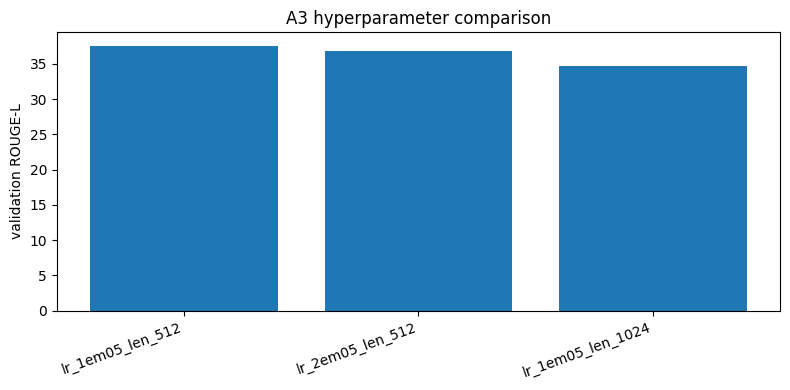

In [17]:
if RUN_TRAINING:
    final_row = length_results.iloc[0].to_dict()
    final_config = {
        "selection_dataset": "A3_train_validation_only",
        "selection_metric": "validation_rougeL_desc_then_validation_loss_asc",
        "model_id": MODEL_ID,
        "model_revision": model_revision,
        "seed": SEED,
        "learning_rate": float(final_row["learning_rate"]),
        "max_source_length": int(final_row["max_source_length"]),
        "max_target_length": MAX_TARGET_LENGTH,
        "train_batch_size": int(final_row["train_batch_size"]),
        "gradient_accumulation_steps": int(final_row["gradient_accumulation_steps"]),
        "effective_batch_size": int(final_row["effective_batch_size"]),
        "max_epochs": MAX_EPOCHS,
        "early_stopping_patience": EARLY_STOPPING_PATIENCE,
        "min_delta": MIN_DELTA,
        "selected_trial": final_row["trial"],
        "selected_best_epoch": int(final_row["best_epoch"]),
        "selected_validation_loss": float(final_row["best_validation_loss"]),
        "selected_validation_rougeL": float(final_row["rougeL"]),
        "test_used_for_selection": False,
        "generation": {"num_beams": 1, "do_sample": False},
    }
    (RESULTS / "selected_hyperparameters.json").write_text(
        json.dumps(final_config, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    display(pd.Series(final_config, name="selected_hyperparameters"))

    comparison_results = pd.concat([
        stage1_results.assign(stage="learning_rate_512"),
        pd.DataFrame([result_1024]).assign(stage="source_length_1024"),
    ], ignore_index=True)
    comparison_results.to_csv(
        RESULTS / "all_trial_results.csv", index=False, encoding="utf-8-sig"
    )

    plot_df = comparison_results.drop_duplicates("trial")
    plt.figure(figsize=(8, 4))
    plt.bar(plot_df["trial"], plot_df["rougeL"])
    plt.ylabel("validation ROUGE-L")
    plt.title("A3 hyperparameter comparison")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(RESULTS / "validation_rougeL_comparison.png", dpi=160)
    plt.show()
else:
    print("RUN_TRAINING=False: 최종 설정은 학습 후 저장됩니다.")

In [18]:
run_config = {
    "purpose": "A3 hyperparameter tuning using validation only",
    "model_id": MODEL_ID,
    "model_revision": model_revision,
    "seed": SEED,
    "learning_rates": LEARNING_RATES,
    "source_lengths": [512, 1024],
    "max_target_length": MAX_TARGET_LENGTH,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "min_delta": MIN_DELTA,
    "test_used": False,
}
(RESULTS / "run_config.json").write_text(
    json.dumps(run_config, ensure_ascii=False, indent=2), encoding="utf-8"
)

print("저장 예정/완료 파일:")
for path in sorted(RESULTS.rglob("*")):
    if path.is_file():
        print("-", path.relative_to(PROJECT))

저장 예정/완료 파일:
- results\05-2_hyperparameter_tuning\all_trial_results.csv
- results\05-2_hyperparameter_tuning\dataset_counts.csv
- results\05-2_hyperparameter_tuning\lr_1em05_len_1024\loss_curve.png
- results\05-2_hyperparameter_tuning\lr_1em05_len_1024\loss_history.csv
- results\05-2_hyperparameter_tuning\lr_1em05_len_1024\validation_metrics.json
- results\05-2_hyperparameter_tuning\lr_1em05_len_1024\validation_predictions.csv
- results\05-2_hyperparameter_tuning\lr_1em05_len_512\loss_curve.png
- results\05-2_hyperparameter_tuning\lr_1em05_len_512\loss_history.csv
- results\05-2_hyperparameter_tuning\lr_1em05_len_512\validation_metrics.json
- results\05-2_hyperparameter_tuning\lr_1em05_len_512\validation_predictions.csv
- results\05-2_hyperparameter_tuning\lr_2em05_len_512\loss_curve.png
- results\05-2_hyperparameter_tuning\lr_2em05_len_512\loss_history.csv
- results\05-2_hyperparameter_tuning\lr_2em05_len_512\validation_metrics.json
- results\05-2_hyperparameter_tuning\lr_2em05_len_51